# 03 · Health indicators and normal ranges (Phase 5, step 1)

**Goal.** Layer 3 watches the car between fault codes. Every trip produces a handful of
**health indicators**: physical numbers that drift when a part starts to fail. Step 2
will build the detector; this notebook settles:
1. **what each indicator is, and its gate**, the conditions under which it means something;
2. **how often it's available** (gate coverage);
3. **what normal looks like**: within one car (noise) and between cars (why each car
   needs its own baseline);
4. **population priors** for a new car, per engine family.

**Data**
| Source | Used for |
|---|---|
| Simulator (5 profiles, Lagos schedule, through the virtual Freematics device) | every indicator; clean fleet, plus one car per fault to check each indicator responds |
| VED (264 petrol cars, Michigan, real OBD-II) | fuel trims, idle airflow, idle RPM spread, high-RPM share: real normal ranges and priors |
| KIT (one Seat Leon, real) | warm-up time, and MAF vs MAP on a real car |

The indicator code is `ml/health/indicators.py`, plain functions that step 4 promotes to the
backend unchanged. Its unit tests are in `ml/tests/test_indicators.py`.

**Outputs:** `ml/reports/phase5_indicators.md` (findings) and `ml/reports/phase5_indicators.yaml`
(gates and priors; all `SEED - validate`).

In [1]:
import os, sys, time, re, math
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from dotenv import load_dotenv

REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd().resolve().parent
load_dotenv(REPO / ".env")
DATASETS_DIR = Path(os.environ["DATASETS_DIR"])
RAW, INTERIM = DATASETS_DIR / "raw", DATASETS_DIR / "interim"
REBUILD_CACHE = os.environ.get("REBUILD_CACHE", "0") == "1"
sys.path[:0] = [str(REPO), str(REPO / "simulator")]
pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7, 3.2)})

from ml.health.indicators import DEFAULTS, INDICATORS, TripInput, compute
from ml.health.sim_io import trips_from_run
from autocare_sim.device import Device
from autocare_sim.faults import fault
from autocare_sim.run import simulate

OUT = {"version": 1, "gates": dict(DEFAULTS)}
OUT["gates"]["cruise_kmh"] = list(DEFAULTS["cruise_kmh"])
MAD_K = 1.4826  # MAD x 1.4826 = standard deviation, for normal data

def rmad(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return float(MAD_K * np.median(np.abs(x - np.median(x)))) if len(x) else np.nan

def pct(s, ps=(10, 50, 90), nd=3):
    s = pd.Series(s).dropna()
    return {f"p{p}": round(float(np.percentile(s, p)), nd) for p in ps} | {"n": int(len(s))}

## 1. The indicators and their gates

| Indicator | Gate (when it's valid) | Early sign of |
|---|---|---|
| `batt_rest_v` | the first cranking samples, before the starter engages, after ≥ 1 h parked (H3) | weak battery, parasitic drain |
| `batt_crank_min_v` | every start (the 50 Hz cranking trace) | weak battery |
| `charging_v_idle` | warm idle ≥ 30 s; device battery reading, else ECU voltage | failing alternator |
| `warmup_s`, `coolant_10min_c` | cold start (coolant < 40 °C) | stuck-open thermostat |
| `coolant_idle_peak_c`, `overheat_s` | warm idle / any time | low coolant, fan or radiator |
| `trim_idle_bN`, `trim_cruise_bN` | warm; idle ≥ 30 s / steady 50–110 km/h ≥ 30 s; STFT + LTFT | vacuum leak (lean at idle only), fuel delivery (lean everywhere) |
| `ltft_b1` | warm | slow drift over weeks |
| `maf_idle_norm` | warm idle: MAF per litre per 1,000 rpm | dirty MAF |
| `maf_vs_map` | warm, running: MAF ÷ the speed-density prediction from MAP and IAT | dirty MAF, intake leak |
| `idle_rpm_std` | warm idle: RPM spread inside each window | misfire, rough idle |
| `km_since_clear` | trip start (PID 0x31) | codes recently cleared |
| `high_rpm_share` | running ≥ 60 s: share of time ≥ 4,000 rpm | driving stress |

**"Warm idle"** = coolant ≥ 80 °C, speed 0, RPM < 1,100, for ≥ 30 s (H1). Data with no
coolant signal (VED) counts as warm after 10 minutes of the trip.

**Why MAF vs MAP and not MAF vs load.** The car's "absolute load" (PID 0x43) is computed by
the ECU *from* the MAF reading, so comparing them only checks the ECU's arithmetic: a dirty
MAF would move both. Manifold pressure (MAP) is measured by a separate sensor. From MAP,
intake air temperature and engine size, physics predicts the airflow ("speed-density":
air mass = pressure ÷ (gas constant × temperature) × displacement × rpm ÷ 120). The car's
true breathing efficiency is unknown but stable, so the car's own baseline absorbs it.

**O2 sensors and the catalyst** are covered by Mode 06 in step 3 (decision Q1); they aren't
in this notebook.

## 2. A clean simulated fleet

Five profiles × two seeds × 30 days of Lagos driving, through the virtual device (its
polling, noise and dropouts), so the indicators see what the backend will store.

In [2]:
PROFILES = {  # profile: (displacement L, cylinders)
    "toyota_corolla_1_8_2009": (1.8, 4), "toyota_camry_2_4_2007": (2.4, 4),
    "honda_accord_2_4_2008": (2.4, 4), "lexus_rx350_3_5_2010": (3.5, 6),
    "toyota_sienna_3_5_2011": (3.5, 6),
}

def family(cyl, disp):
    band = ("<=1.6" if disp <= 1.6 else "1.7-2.0" if disp <= 2.0 else "2.1-2.5" if disp <= 2.5
            else "2.6-3.0" if disp <= 3.0 else "3.1-3.6" if disp <= 3.6 else ">3.6")
    return f"{cyl}-cyl {band} L"

def sim_rows(pid, days, seed, faults=None, car=None):
    disp, cyl = PROFILES[pid]
    tl = simulate(pid, days=days, seed=seed, faults=faults)
    run_ = Device(f"SIM-{seed}", tl, seed=seed, clock_faults=False).run(drain_days=0)
    trips = trips_from_run(run_)
    rows = []
    for n, tr in enumerate(tl.trips, start=1):
        if n not in trips:
            continue
        v = compute(TripInput(trips[n], displacement_l=disp, parked_before_s=tr.parked_before_s))
        row = {"car": car or f"{pid}#{seed}", "profile": pid, "family": family(cyl, disp),
               "trip": n, "day": tr.days, "km": tr.out.distance_km, "dur_s": tr.duration_s,
               "parked_s": tr.parked_before_s, "cold_start": float(trips[n]["coolant"][1][0]) < DEFAULTS["cold_start_c"]
               if "coolant" in trips[n] else False}
        row |= {k: x.value for k, x in v.items()}
        rows.append(row)
    return rows, tl

cache = INTERIM / "phase5_sim_clean.parquet"
if cache.exists() and not REBUILD_CACHE:
    sim = pd.read_parquet(cache)
else:
    t0, rows = time.time(), []
    for pid in PROFILES:
        for seed in (101, 102):
            rows += sim_rows(pid, 30, seed)[0]
    sim = pd.DataFrame(rows)
    sim.to_parquet(cache)
    print(f"simulated in {time.time() - t0:.0f} s")
IND = [k for k in INDICATORS if k in sim.columns]
print(f"{len(sim)} trips, {sim.car.nunique()} cars, {sim.km.sum():,.0f} km")

731 trips, 10 cars, 8,703 km


### 2a. Gate coverage

For most indicators the denominator is every trip whose car reports the inputs. Two only
exist on particular trips, so their denominator is those trips:
- **warm-up** values exist only after a cold start;
- **resting voltage** only after ≥ 1 h parked.

Fuel trims at cruise need a steady stretch at 50–110 km/h, which Lagos traffic often
doesn't give: that's a real limit, reported as found.

In [3]:
DENOM = {"warmup_s": "cold_start", "coolant_10min_c": "cold_start",
         "batt_rest_v": "parked_1h"}
sim["parked_1h"] = sim.parked_s >= DEFAULTS["rest_parked_s"]
cov = []
for k in IND:
    has_inputs = sim.groupby("car")[k].transform(lambda s: s.notna().any())
    base = sim[has_inputs]
    if k in DENOM:
        base = base[base[DENOM[k]]]
    days = base.assign(d=base.day.astype(int)).groupby(["car", "d"])[k].apply(lambda s: s.notna().any())
    cov.append({"indicator": k, "trips": len(base), "coverage": base[k].notna().mean(),
                "days_with_value": days.mean()})
cov = pd.DataFrame(cov).set_index("indicator").round(3)
print(cov)
OUT["coverage_sim"] = cov.to_dict("index")

                     trips  coverage  days_with_value
indicator                                            
batt_rest_v            607     1.000            1.000
batt_crank_min_v       731     1.000            1.000
charging_v_idle        731     0.527            0.787
warmup_s               602     0.626            0.817
coolant_10min_c        602     0.699            0.870
coolant_idle_peak_c    731     0.527            0.787
overheat_s             731     1.000            1.000
trim_idle_b1           731     0.527            0.787
trim_idle_b2           293     0.539            0.833
trim_cruise_b1         731     0.423            0.683
trim_cruise_b2         293     0.420            0.700
ltft_b1                731     0.639            0.843
maf_idle_norm          731     0.527            0.787
maf_vs_map             586     0.621            0.842
idle_rpm_std           731     0.527            0.787
km_since_clear         731     1.000            1.000
high_rpm_share         731  

### 2b. Within-car noise vs between-car spread

- **Within-car spread** (robust: MAD × 1.4826) is the trip-to-trip noise of one healthy car.
- **Between-car spread** is how far healthy cars differ from each other.

When between ≫ within, a population threshold would be far too loose for any single car.
That's why each car gets its **own** baseline, and a prior is only a starting point.

In [4]:
def spread_table(df, inds, group="car"):
    rows = []
    for k in inds:
        g = df.groupby(group)[k]
        med = g.median().dropna()
        within = g.apply(rmad).dropna()
        if len(med) == 0:
            continue
        rows.append({"indicator": k, "cars": len(med), "median": float(np.median(med)),
                     "within_car": float(np.median(within)), "between_car": rmad(med),
                     "ratio": rmad(med) / float(np.median(within)) if np.median(within) > 0 else np.nan})
    return pd.DataFrame(rows).set_index("indicator")

sim_spread = spread_table(sim, IND).round(3)
print(sim_spread)

                     cars   median  within_car  between_car  ratio
indicator                                                         
batt_rest_v            10   12.655       0.022        0.004  0.167
batt_crank_min_v       10    9.340       0.030        0.000  0.000
charging_v_idle        10   14.090       0.015        0.000  0.000
warmup_s               10  858.007      41.549        3.019  0.073
coolant_10min_c        10   72.001       1.482        0.001  0.001
coolant_idle_peak_c    10   90.000       1.483        0.000  0.000
overheat_s             10    0.000       0.000        0.000    NaN
trim_idle_b1           10    1.050       0.297        2.298  7.750
trim_idle_b2            4    1.450       0.222        1.779  8.000
trim_cruise_b1         10    1.100       0.445        2.224  5.000
trim_cruise_b2          4    1.500       0.371        1.779  4.800
ltft_b1                10    1.050       0.000        2.298    NaN
maf_idle_norm          10    2.537       0.009        0.050  5

## 3. Does each indicator respond to its fault?

One Corolla (two for the V6-only check) per library fault, 45 days, compared with the same
car's first 3 days. The shift is shown in units of the clean fleet's **within-car spread**,
so "8" means the value moved 8 typical trip-to-trip wobbles. This isn't the detector (that's
step 2): it only checks each fault bends the indicator meant to catch it.

In [5]:
EXPECT = {  # fault: indicators that should move
    "weak_battery": ["batt_rest_v", "batt_crank_min_v"],
    "failing_alternator": ["charging_v_idle"],
    "stuck_open_thermostat": ["warmup_s", "coolant_10min_c"],
    "low_coolant": ["coolant_idle_peak_c", "overheat_s"],
    "vacuum_leak": ["trim_idle_b1", "trim_cruise_b1", "maf_vs_map"],
    "dirty_maf": ["maf_vs_map", "maf_idle_norm", "trim_cruise_b1"],
    "misfire": ["idle_rpm_std"],
    "ageing_o2": [], "catalyst_degradation": [],  # Mode 06 (step 3)
}
cache_f = INTERIM / "phase5_sim_faults.parquet"
if cache_f.exists() and not REBUILD_CACHE:
    fsim = pd.read_parquet(cache_f)
else:
    t0, rows = time.time(), []
    for k, name in enumerate(EXPECT):
        rows += [r | {"fault": name} for r in
                 sim_rows("toyota_corolla_1_8_2009", 45, 300 + k, faults=[fault(name)], car=name)[0]]
    fsim = pd.DataFrame(rows)
    fsim.to_parquet(cache_f)
    print(f"simulated in {time.time() - t0:.0f} s")

within = sim[sim.profile == "toyota_corolla_1_8_2009"].groupby("car")[IND].agg(rmad).median()
resp = []
for name, inds in EXPECT.items():
    d = fsim[fsim.fault == name]
    early, late = d[d.day < 3], d[d.day >= d.day.max() - 7]
    for k in inds:
        if k not in d or early[k].notna().sum() == 0 or late[k].notna().sum() == 0:
            resp.append({"fault": name, "indicator": k, "early": np.nan, "late": np.nan, "shift_sd": np.nan})
            continue
        e, l = early[k].median(), late[k].median()
        sd = within.get(k, np.nan)
        resp.append({"fault": name, "indicator": k, "early": e, "late": l,
                     "shift_sd": (l - e) / sd if sd and sd > 0 else np.nan})
resp = pd.DataFrame(resp).round(3)
print(resp.to_string(index=False))
OUT["fault_response"] = resp.replace({np.nan: None}).to_dict("records")

                fault           indicator  early    late  shift_sd
         weak_battery         batt_rest_v 12.658  12.058   -32.376
         weak_battery    batt_crank_min_v  9.325   6.930   -64.616
   failing_alternator     charging_v_idle 14.105  12.280  -123.095
stuck_open_thermostat            warmup_s    NaN     NaN       NaN
stuck_open_thermostat     coolant_10min_c 71.002  47.000   -16.189
          low_coolant coolant_idle_peak_c 90.000 115.500    17.200
          low_coolant          overheat_s  0.000 536.000       NaN
          vacuum_leak        trim_idle_b1 -0.350  63.100   244.551
          vacuum_leak      trim_cruise_b1 -0.400  20.050    45.978
          vacuum_leak          maf_vs_map  0.924   0.954     2.165
            dirty_maf          maf_vs_map  0.969   0.755   -15.560
            dirty_maf       maf_idle_norm  2.530   1.965   -74.632
            dirty_maf      trim_cruise_b1 -3.650  25.350    65.201
              misfire        idle_rpm_std 15.559  23.268    16

## 4. VED: real normal ranges

The 264 petrol cars, read once from the raw weekly CSVs (≈ 3.2 GB) and cached. VED has no
coolant signal, so "warm" = more than 10 minutes into the trip. It has no MAP either, so
there's no `maf_vs_map` here. Only trips of at least 10 minutes can give warm values.

In [6]:
static = pd.read_excel(RAW / "ved/static/VED_Static_Data_ICE&HEV.xlsx")
ice = static[static["Vehicle Type"] == "ICE"].copy()
def parse_engine(s):
    m = re.match(r"(\d+)-\w+\s+([\d.]+)L", str(s))
    return (int(m.group(1)), float(m.group(2))) if m else (None, None)
ice[["cyl", "disp"]] = ice["Engine Configuration & Displacement"].apply(lambda s: pd.Series(parse_engine(s)))
ice["turbo"] = ice["Engine Configuration & Displacement"].str.contains("T/C", na=False)
ice = ice.dropna(subset=["cyl", "disp"])
ICE = dict(zip(ice.VehId, zip(ice.cyl.astype(int), ice.disp)))
print(f"{len(ICE)} petrol cars with a known engine; turbo: {int(ice.turbo.sum())}")

COLS = {"Vehicle Speed[km/h]": "speed", "Engine RPM[RPM]": "rpm", "MAF[g/sec]": "maf",
        "Absolute Load[%]": "abs_load", "OAT[DegC]": "ambient",
        "Short Term Fuel Trim Bank 1[%]": "stft_b1", "Short Term Fuel Trim Bank 2[%]": "stft_b2",
        "Long Term Fuel Trim Bank 1[%]": "ltft_b1", "Long Term Fuel Trim Bank 2[%]": "ltft_b2"}

def ved_trip_rows(df):
    rows = []
    for (veh, trip), d in df.groupby(["VehId", "Trip"], sort=False):
        t = d["Timestamp(ms)"].to_numpy() / 1000.0
        if t[-1] - t[0] < DEFAULTS["assume_warm_after_s"] + 60:
            continue
        sig = {}
        for name in COLS.values():
            v = d[name].to_numpy()
            ok = np.isfinite(v)
            if ok.sum() >= 2:
                sig[name] = (t[ok], v[ok])
        cyl, disp = ICE[veh]
        v = compute(TripInput(sig, displacement_l=disp, has_coolant=False))
        rows.append({"car": int(veh), "trip": int(trip), "family": family(cyl, disp),
                     "turbo": bool(ice.set_index("VehId").turbo.get(veh, False)),
                     "dur_s": t[-1] - t[0], "n_rows": len(d)} | {k: x.value for k, x in v.items()})
    return rows

cache_v = INTERIM / "phase5_ved_indicators.parquet"
if cache_v.exists() and not REBUILD_CACHE:
    ved = pd.read_parquet(cache_v)
else:
    t0, rows = time.time(), []
    files = sorted((RAW / "ved/dynamic").rglob("VED_*_week.csv"))
    for f in files:
        df = pd.read_csv(f, usecols=["VehId", "Trip", "Timestamp(ms)", *COLS])
        df = df[df.VehId.isin(ICE.keys())].rename(columns=COLS)
        rows += ved_trip_rows(df)
    ved = pd.DataFrame(rows)
    # A trip that runs across two weekly files is computed twice: keep the longer part.
    ved = ved.sort_values("n_rows").drop_duplicates(["car", "trip"], keep="last")
    ved.to_parquet(cache_v)
    print(f"read {len(files)} files in {time.time() - t0:.0f} s")
VIND = [k for k in INDICATORS if k in ved.columns]
print(f"{len(ved)} trips of 11+ min, {ved.car.nunique()} cars; indicators: {VIND}")

241 petrol cars with a known engine; turbo: 18
4502 trips of 11+ min, 219 cars; indicators: ['trim_idle_b1', 'trim_idle_b2', 'trim_cruise_b1', 'trim_cruise_b2', 'ltft_b1', 'maf_idle_norm', 'idle_rpm_std', 'high_rpm_share']


In [7]:
ved_cov = pd.Series({k: ved[ved.groupby('car')[k].transform(lambda s: s.notna().any())][k].notna().mean()
                     for k in VIND}).round(3)
print("VED coverage (trips of 11+ min, cars that report the inputs):"); print(ved_cov)
ved_spread = spread_table(ved, VIND).round(3)
print(ved_spread)
OUT["coverage_ved"] = ved_cov.to_dict()

VED coverage (trips of 11+ min, cars that report the inputs):
trim_idle_b1      0.474
trim_idle_b2      0.545
trim_cruise_b1    0.577
trim_cruise_b2    0.644
ltft_b1           0.823
maf_idle_norm     0.592
idle_rpm_std      0.580
high_rpm_share    0.998
dtype: float64
                cars  median  within_car  between_car  ratio
indicator                                                   
trim_idle_b1     188   0.781       2.317        4.633  2.000
trim_idle_b2      69   1.562       1.737        5.791  3.333
trim_cruise_b1   196   0.781       1.303        4.633  3.556
trim_cruise_b2    69   1.562       1.737        4.633  2.667
ltft_b1          214   0.391       1.158        3.185  2.750
maf_idle_norm    148   1.926       0.108        0.316  2.919
idle_rpm_std     199  14.212       6.315        9.043  1.432
high_rpm_share   219   0.000       0.000        0.000    NaN


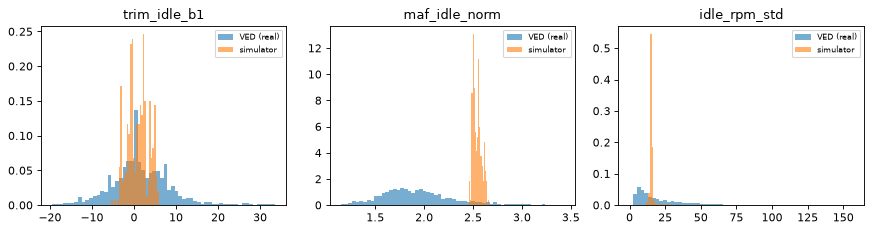

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3))
for ax, k in zip(axs, ["trim_idle_b1", "maf_idle_norm", "idle_rpm_std"]):
    ax.hist(ved[k].dropna(), bins=60, alpha=0.6, density=True, label="VED (real)")
    ax.hist(sim[k].dropna(), bins=30, alpha=0.6, density=True, label="simulator")
    ax.set_title(k); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. KIT: real warm-ups and MAF vs MAP

One Seat Leon over 81 trips in summer. Its engine isn't recorded, so the airflow numbers use
an assumed 1.4 L. The absolute level is therefore arbitrary; only how steady it is from
trip to trip matters (that's all a per-car baseline needs). The `Messfehler` (measurement
error) file is excluded.

In [9]:
KCOLS = {"engine coolant temperature": "coolant", "intake manifold absolute pressure": "map",
         "engine rpm": "rpm", "vehicle speed sensor": "speed", "intake air temperature": "iat",
         "air flow rate from mass flow sensor": "maf", "ambient air temperature": "ambient"}

def kit_trip(path):
    df = pd.read_csv(path)
    df.columns = [re.sub(r"\s*\[.*$", "", c).strip().lower() for c in df.columns]
    df = df.rename(columns=KCOLS)
    t = pd.to_datetime(df["time"], format="%H:%M:%S.%f", errors="coerce")
    t = (t - t.iloc[0]).dt.total_seconds().to_numpy()
    sig = {}
    for name in KCOLS.values():
        if name in df:
            v = pd.to_numeric(df[name], errors="coerce").to_numpy()
            # Rows repeat the last value of every column except the one just read: keep changes.
            ok = np.isfinite(v) & np.isfinite(t)
            keep = ok & np.r_[True, np.diff(np.where(ok, v, np.nan)) != 0]
            if keep.sum() >= 2:
                sig[name] = (t[keep], v[keep])
    return sig

krows = []
for p in sorted((RAW / "kit_obd").glob("*.csv")):
    if "Messfehler" in p.name:
        continue
    sig = kit_trip(p)
    v = compute(TripInput(sig, displacement_l=1.4))
    iat0 = float(sig["iat"][1][0]) if "iat" in sig else np.nan
    krows.append({"file": p.name, "iat_start": iat0,
                  "coolant_start": float(sig["coolant"][1][0]) if "coolant" in sig else np.nan}
                 | {k: x.value for k, x in v.items()})
kit = pd.DataFrame(krows)
print(f"{len(kit)} KIT trips; cold starts: {int((kit.coolant_start < DEFAULTS['cold_start_c']).sum())}")
kcols = [c for c in ["warmup_s", "coolant_10min_c", "maf_vs_map", "maf_idle_norm",
                     "coolant_idle_peak_c", "idle_rpm_std"] if c in kit]
print(kit[kcols].describe().round(3))
print("not available on KIT:", [c for c in ["maf_idle_norm", "idle_rpm_std"] if c not in kit])
kit_mvm_cv = rmad(kit.maf_vs_map) / kit.maf_vs_map.median()
print(f"KIT maf_vs_map trip-to-trip spread: {kit_mvm_cv:.1%} of its median")

80 KIT trips; cold starts: 62
       warmup_s  coolant_10min_c  maf_vs_map
count    57.000           47.000      75.000
mean    756.092           68.787       0.710
std     300.444           13.587       0.064
min     361.368           43.193       0.556
25%     562.139           58.537       0.670
50%     735.860           65.565       0.698
75%     818.168           82.179       0.750
max    2014.851           93.413       0.896
not available on KIT: ['maf_idle_norm', 'idle_rpm_std']
KIT maf_vs_map trip-to-trip spread: 10.2% of its median


### Should warm-up time be normalised by the starting temperature?

A cold morning makes warm-up longer, with nothing wrong. If warm-up time depends strongly on
the starting intake air temperature, the detector should compare the *residual* (actual
minus expected for that temperature). Lagos mornings vary less than Karlsruhe's, so the
simulator's slope is checked too.

In [10]:
def slope(df, x, y):
    d = df[[x, y]].dropna()
    if len(d) < 8:
        return np.nan, np.nan, len(d)
    b, a = np.polyfit(d[x], d[y], 1)
    r = np.corrcoef(d[x], d[y])[0, 1]
    return float(b), float(r), len(d)

kb, kr, kn = slope(kit, "iat_start", "warmup_s")
sim_cold = sim[sim.cold_start].copy()
first_iat = []  # the simulator's start IAT isn't in the indicator table; use ambient via parked trips
print(f"KIT: warm-up {kb:+.1f} s per °C of start IAT (r = {kr:.2f}, n = {kn})")
OUT["warmup_iat_slope"] = {"kit_s_per_degc": None if np.isnan(kb) else round(kb, 2),
                           "kit_r": None if np.isnan(kr) else round(kr, 2), "kit_n": kn}

KIT: warm-up -10.7 s per °C of start IAT (r = -0.31, n = 57)


## 6. Population priors per engine family

For a new car's first ~10 trips (step 2's burn-in), each indicator is compared with typical
healthy cars of the same engine family:
- **VED** for fuel trims, idle airflow, idle RPM spread and high-RPM share (real cars, decision Q3);
- **the simulator** for everything VED can't measure (voltages, cooling), with lower confidence.

Each prior records:
- the family's typical value (median of the car medians);
- how much cars differ (between-car spread);
- the typical trip-to-trip noise of one car (within-car spread);
- the number of cars.

In [11]:
VED_PRIORS = ["trim_idle_b1", "trim_idle_b2", "trim_cruise_b1", "trim_cruise_b2", "ltft_b1",
              "maf_idle_norm", "idle_rpm_std", "high_rpm_share"]
def priors(df, inds, source, min_cars):
    out = {}
    for fam, d in df.groupby("family"):
        t = spread_table(d, inds)
        for k, r in t.iterrows():
            if r.cars < min_cars:
                continue
            out.setdefault(fam, {})[k] = {"median": round(float(r["median"]), 4),
                "between_car": round(float(r.between_car), 4), "within_car": round(float(r.within_car), 4),
                "cars": int(r.cars), "source": source}
    return out

pri = priors(ved[~ved.turbo], [k for k in VED_PRIORS if k in ved], "ved", min_cars=5)
sim_only = [k for k in IND if k not in VED_PRIORS]
for fam, d in priors(sim, sim_only, "simulator", min_cars=1).items():
    pri.setdefault(fam, {}).update(d)
for fam, d in priors(sim, [k for k in VED_PRIORS if k in sim], "simulator", min_cars=1).items():
    for k, v in d.items():
        pri.setdefault(fam, {}).setdefault(k, v)  # fill VED gaps (e.g. V6 bank 2) from the sim
OUT["priors"] = pri
print(pd.DataFrame({fam: {k: v["median"] for k, v in d.items()} for fam, d in pri.items()}).round(3))

                     4-cyl 1.7-2.0 L  4-cyl 2.1-2.5 L  4-cyl <=1.6 L  6-cyl 2.6-3.0 L  6-cyl 3.1-3.6 L  6-cyl >3.6 L  8-cyl >3.6 L
trim_idle_b1                   0.195            1.562         -1.562            2.344           -0.586         3.516         0.000
trim_cruise_b1                 0.781            1.562         -1.074            3.320            0.000         0.586         3.906
ltft_b1                        0.000            0.781         -1.562            3.125            0.000         0.781         0.000
maf_idle_norm                  2.004            1.910          2.567            2.023            1.810           NaN         1.896
idle_rpm_std                  16.734           16.078         22.244            9.900           12.056        10.461        17.297
high_rpm_share                 0.000            0.000          0.000            0.000            0.000         0.000         0.000
batt_rest_v                   12.652           12.655            NaN              N

## 7. The step 1 gate

1. Every indicator has a valid value on **≥ 50 %** of the clean trips where its inputs
   exist (H7). For warm-up and resting voltage, that's the trips where they can exist.
2. **Simulator vs VED agree** for the shared indicators. The comparison is the median of
   car medians, simulated 4-cylinder cars against real 4-cylinder non-turbo cars of
   1.7–2.5 L. Tolerances (SEED):
   - trims within 3 percentage points;
   - idle RPM spread and idle airflow within a factor of 0.5–2 and 0.7–1.3.
3. **VED is plausible:** warm-idle total trim within ±10 % on ≥ 90 % of trips; idle airflow
   between 1 and 5 g/s per litre per 1,000 rpm on ≥ 95 %.

In [12]:
checks = []
for k, r in cov.iterrows():
    checks.append((f"coverage {k}", r.coverage >= 0.5, f"{r.coverage:.0%} of {int(r.trips)} trips"))

v4 = ved[(~ved.turbo) & ved.family.isin(["4-cyl 1.7-2.0 L", "4-cyl 2.1-2.5 L"])]
s4 = sim[sim.family.isin(["4-cyl 1.7-2.0 L", "4-cyl 2.1-2.5 L"])]
def mm(df, k):
    return float(df.groupby("car")[k].median().median())
for k, kind, lo, hi in [("trim_idle_b1", "diff", -3, 3), ("trim_cruise_b1", "diff", -3, 3),
                        ("idle_rpm_std", "ratio", 0.5, 2.0), ("maf_idle_norm", "ratio", 0.7, 1.3)]:
    a, b = mm(s4, k), mm(v4, k)
    x = a - b if kind == "diff" else a / b
    checks.append((f"sim vs VED {k}", lo <= x <= hi,
                   f"sim {a:.3f} vs VED {b:.3f} ({'Δ' if kind == 'diff' else '×'} {x:.2f})"))

t = ved.trim_idle_b1.dropna()
checks.append(("VED warm-idle trim within ±10 %", (t.abs() <= 10).mean() >= 0.9,
               f"{(t.abs() <= 10).mean():.1%} of {len(t)} trips"))
m = ved.maf_idle_norm.dropna()
checks.append(("VED idle airflow 1-5 g/s/L/krpm", m.between(1, 5).mean() >= 0.95,
               f"{m.between(1, 5).mean():.1%} of {len(m)} trips"))

gate = pd.DataFrame(checks, columns=["check", "pass", "detail"])
print(gate.to_string(index=False))
print(f"\nGATE: {'PASSED' if gate['pass'].all() else 'FAILED'} ({gate['pass'].sum()} of {len(gate)})")
OUT["gate"] = {"passed": bool(gate["pass"].all()),
               "checks": [{"check": c, "pass": bool(p), "detail": d} for c, p, d in checks]}

                          check  pass                            detail
           coverage batt_rest_v  True                 100% of 607 trips
      coverage batt_crank_min_v  True                 100% of 731 trips
       coverage charging_v_idle  True                  53% of 731 trips
              coverage warmup_s  True                  63% of 602 trips
       coverage coolant_10min_c  True                  70% of 602 trips
   coverage coolant_idle_peak_c  True                  53% of 731 trips
            coverage overheat_s  True                 100% of 731 trips
          coverage trim_idle_b1  True                  53% of 731 trips
          coverage trim_idle_b2  True                  54% of 293 trips
        coverage trim_cruise_b1 False                  42% of 731 trips
        coverage trim_cruise_b2 False                  42% of 293 trips
               coverage ltft_b1  True                  64% of 731 trips
         coverage maf_idle_norm  True                  53% of 73

In [13]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else round(float(o), 4)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
OUT["spread_sim"] = sim_spread.to_dict("index")
OUT["spread_ved"] = ved_spread.to_dict("index")
OUT["note"] = "SEED - validate: gates H1-H3, tolerances and priors; see ml/reports/phase5_indicators.md"
(REPO / "ml/reports/phase5_indicators.yaml").write_text(
    "# Phase 5 step 1 (notebook 03). SEED - validate: every gate and prior here.\n"
    + yaml.safe_dump(clean(OUT), sort_keys=False, width=100), encoding="utf-8")
print("wrote ml/reports/phase5_indicators.yaml")

wrote ml/reports/phase5_indicators.yaml
